#                                                                                 Pretraitement du dataset Titanic :

## Partie 1 : Introduction au Dataset

In [2]:
import numpy as np 
import pandas as pd 
# data visualization
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib import style

In [3]:
data = pd.read_csv('Titanic-Dataset.csv')

### Visualisez les premières lignes du dataset :

In [4]:
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Vérifiez les valeurs manquantes avec

In [5]:

print(data.isna().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


### Afficher les colone qui contient  valeurs manquantes

In [6]:
manquant=data.isnull().sum()

print(manquant[manquant > 0])

Age         177
Cabin       687
Embarked      2
dtype: int64


## Partie 2 : Nettoyage des Données:

### 1.Gestion des valeurs manquantes 

#### Suppression des colonnes avec trop de valeurs manquantes (>40%)

In [7]:

seuil = 0.4  
colonnes_a_supprimer = [col for col in data.columns if data[col].isnull().mean() > seuil]
print("\nColonnes à supprimer (plus de 40% manquantes) :", colonnes_a_supprimer)
data.drop(columns=colonnes_a_supprimer, inplace=True)


Colonnes à supprimer (plus de 40% manquantes) : ['Cabin']


### Remplissage des valeurs manquantes pour les colonnes numériques

In [8]:
colonnes_numeriques = data.select_dtypes(include=[np.number]).columns.tolist()

for col in colonnes_numeriques:
    if data[col].isnull().sum() > 0:
        mediane = data[col].median()
        data[col] = data[col].fillna(mediane)  
        print(f"Colonne numérique '{col}' : valeurs manquantes remplacées par la médiane ({mediane})")

Colonne numérique 'Age' : valeurs manquantes remplacées par la médiane (28.0)


### Remplissage des valeurs manquantes pour les variables catégorielles

In [9]:
# Colonnes catégorielles
colonnes_categorielles = data.select_dtypes(include=[object, 'string']).columns.tolist()

for col in colonnes_categorielles:
    if data[col].isnull().sum() > 0:
        mode = data[col].mode()[0]
        data[col] = data[col].fillna(mode)  # <-- assignation directe
        print(f"Colonne catégorielle '{col}' : valeurs manquantes remplacées par la mode ('{mode}')")

Colonne catégorielle 'Embarked' : valeurs manquantes remplacées par la mode ('S')


### Vérification finale manquantes après nettoyage 

In [10]:

print("Valeurs manquantes après nettoyage :")
print(data.isnull().sum())

Valeurs manquantes après nettoyage :
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


### La séparation des données (Train/Test Split).

In [11]:
from sklearn.model_selection import train_test_split

X= data.drop(columns=['Survived'])
Y=data['Survived']
X_train,X_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

### 2.Gestion des valeurs aberrantes :

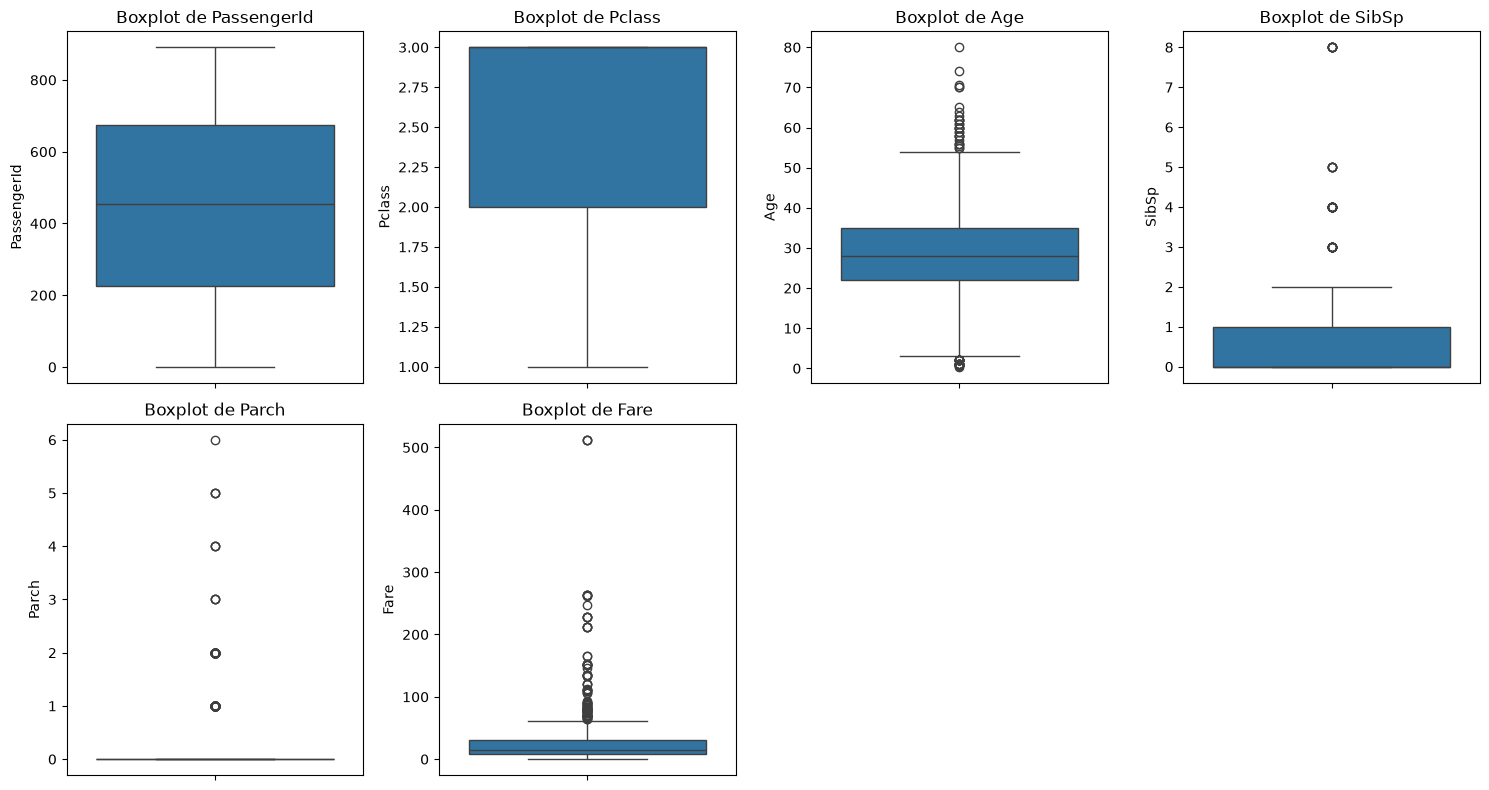

In [12]:
# Colonnes numériques
colonnes_numeriques = X_train.select_dtypes(include=[np.number]).columns.tolist()

# Création de boxplots pour chaque colonne numérique
plt.figure(figsize=(15, 8))
for i, col in enumerate(colonnes_numeriques, 1):
    plt.subplot(2, 4, i)  # disposition des subplots
    sns.boxplot(y=X_train[col])
    plt.title(f'Boxplot de {col}')

plt.tight_layout()
plt.show()

### Remplacez les valeurs aberrantes par la médiane de la variable

In [13]:
def cap_outliers_iqr(d, col):
    Q1 = d[col].quantile(0.25)
    Q3 = d[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    d[col] = d[col].astype(float)
    d[col] = d[col].clip(lower=lower, upper=upper)
    return d

for col in ['Fare', 'Age', 'SibSp', 'Parch']:
    X_train = cap_outliers_iqr(X_train, col)

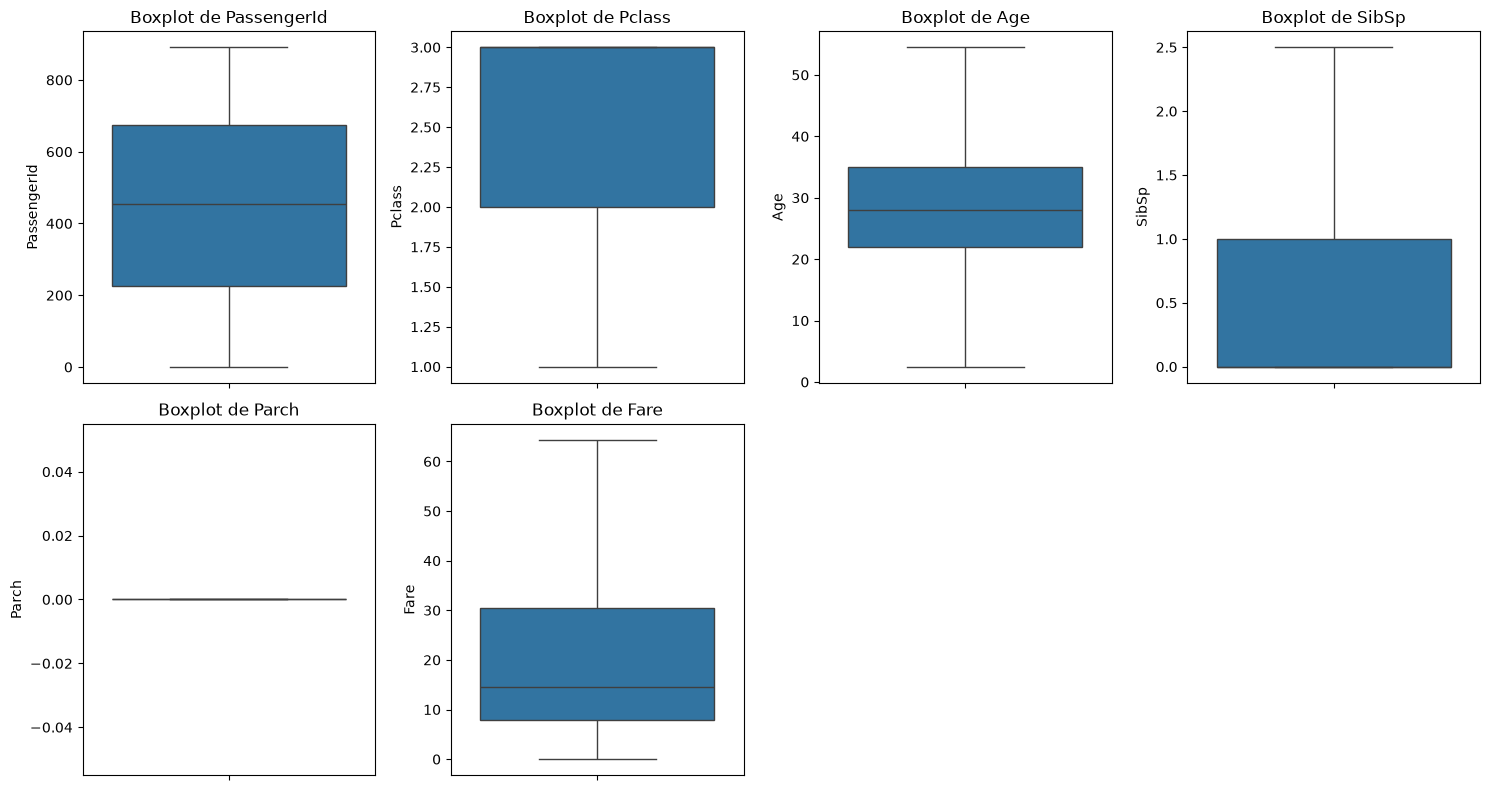

In [14]:
# Colonnes numériques
colonnes_numeriques = X_train.select_dtypes(include=[np.number]).columns.tolist()

# Création de boxplots pour chaque colonne numérique
plt.figure(figsize=(15, 8))
for i, col in enumerate(colonnes_numeriques, 1):
    plt.subplot(2, 4, i)  # disposition des subplots
    sns.boxplot(y=X_train[col])
    plt.title(f'Boxplot de {col}')

plt.tight_layout()
plt.show()

## Partie 3 : Transformation des Données : 

In [15]:
# Colonnes catégorielles de data train  restantes après nettoyage
colonnes_categorielles =X_train.select_dtypes(include=[object, 'string']).columns.tolist()
print("Colonnes catégorielles :", colonnes_categorielles)

Colonnes catégorielles : ['Name', 'Sex', 'Ticket', 'Embarked']


In [16]:
# Colonnes catégoriellesde data test restantes après nettoyage
colonnes_categorielles =X_test.select_dtypes(include=[object, 'string']).columns.tolist()
print("Colonnes catégorielles :", colonnes_categorielles)

Colonnes catégorielles : ['Name', 'Sex', 'Ticket', 'Embarked']


### 1.Encodage des variables catégorielles :

In [17]:
X_train = pd.get_dummies(X_train, columns=['Sex', 'Embarked'])

In [18]:
X_train = X_train.replace({True: 1, False: 0})

In [19]:
X_train

,PassengerId,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
331,332,1,"Partner, Mr. Austen",45.5,0.0,0.0,113043,28.5000,0,1,0,0,1
733,734,2,"Berriman, Mr. William John",23.0,0.0,0.0,28425,13.0000,0,1,0,0,1
382,383,3,"Tikkanen, Mr. Juho",32.0,0.0,0.0,STON/O 2. 3101293,7.9250,0,1,0,0,1
704,705,3,"Hansen, Mr. Henrik Juul",26.0,1.0,0.0,350025,7.8542,0,1,0,0,1
813,814,3,"Andersson, Miss. Ebba Iris Alfrida",6.0,2.5,0.0,347082,31.2750,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,107,3,"Salkjelsvik, Miss. Anna Kristine",21.0,0.0,0.0,343120,7.6500,1,0,0,0,1
270,271,1,"Cairns, Mr. Alexander",28.0,0.0,0.0,113798,31.0000,0,1,0,0,1
860,861,3,"Hansen, Mr. Claus Peter",41.0,2.0,0.0,350026,14.1083,0,1,0,0,1
435,436,1,"Carter, Miss. Lucile Polk",14.0,1.0,0.0,113760,64.3625,1,0,0,0,1


In [20]:
X_test = pd.get_dummies(X_test, columns=['Sex', 'Embarked'])

In [21]:
X_test = X_test.replace({True: 1, False: 0})

In [22]:
X_test

,PassengerId,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
709,710,3,"Moubarek, Master. Halim Gonios (""William George"")",28.0,1,1,2661,15.2458,0,1,1,0,0
439,440,2,"Kvillner, Mr. Johan Henrik Johannesson",31.0,0,0,C.A. 18723,10.5000,0,1,0,0,1
840,841,3,"Alhomaki, Mr. Ilmari Rudolf",20.0,0,0,SOTON/O2 3101287,7.9250,0,1,0,0,1
720,721,2,"Harper, Miss. Annie Jessie ""Nina""",6.0,0,1,248727,33.0000,1,0,0,0,1
39,40,3,"Nicola-Yarred, Miss. Jamila",14.0,1,0,2651,11.2417,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
433,434,3,"Kallio, Mr. Nikolai Erland",17.0,0,0,STON/O 2. 3101274,7.1250,0,1,0,0,1
773,774,3,"Elias, Mr. Dibo",28.0,0,0,2674,7.2250,0,1,1,0,0
25,26,3,"Asplund, Mrs. Carl Oscar (Selma Augusta Emilia...",38.0,1,5,347077,31.3875,1,0,0,0,1
84,85,2,"Ilett, Miss. Bertha",17.0,0,0,SO/C 14885,10.5000,1,0,0,0,1


### 2.Normalisation et Standardisation des données : 

In [23]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler
colonnes_numeriques = X_train.select_dtypes(include=[np.number]).columns.tolist()
scaler_minmax = MinMaxScaler()
#Normalisation (Min-Max scaling) : 
X_normalized = X_train.copy()
X_normalized[colonnes_numeriques] = scaler_minmax.fit_transform(X_train[colonnes_numeriques])
scaler_standard = StandardScaler()
#Standardisation (Z-score) :
X_standardized = X_train.copy()
X_standardized[colonnes_numeriques] = scaler_standard.fit_transform(X_train[colonnes_numeriques])

### Comparaison en utilisant des histogrammes :

### Data Train:

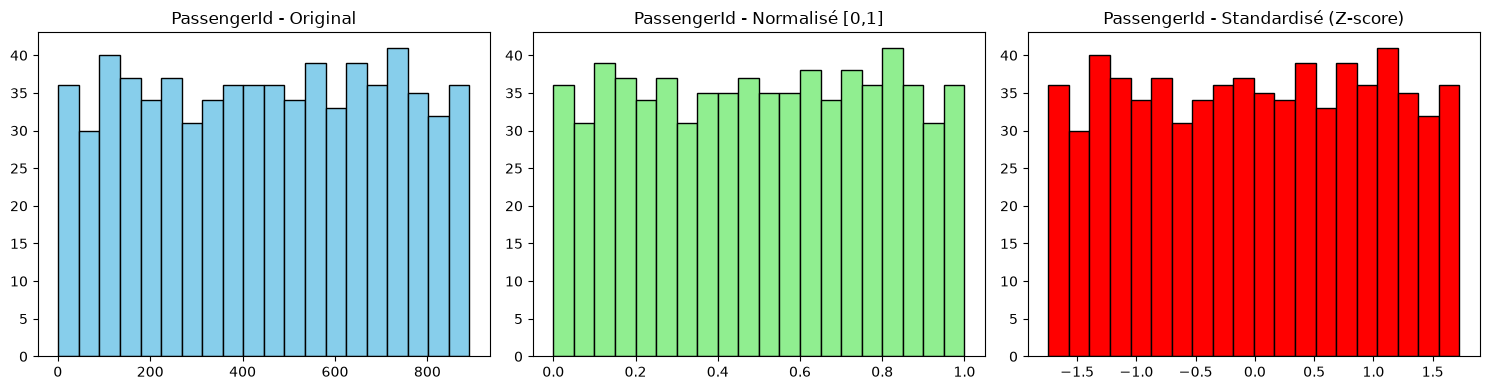

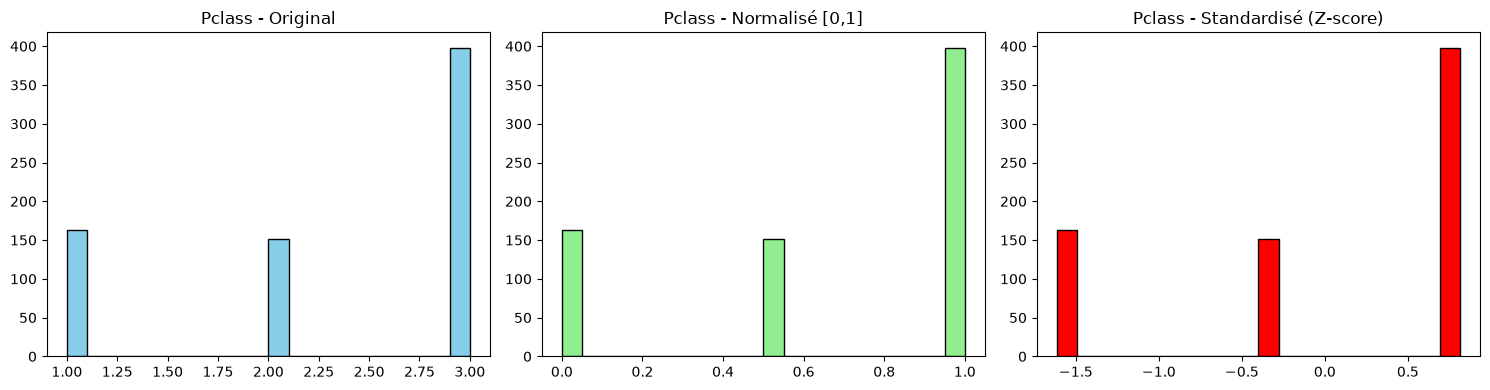

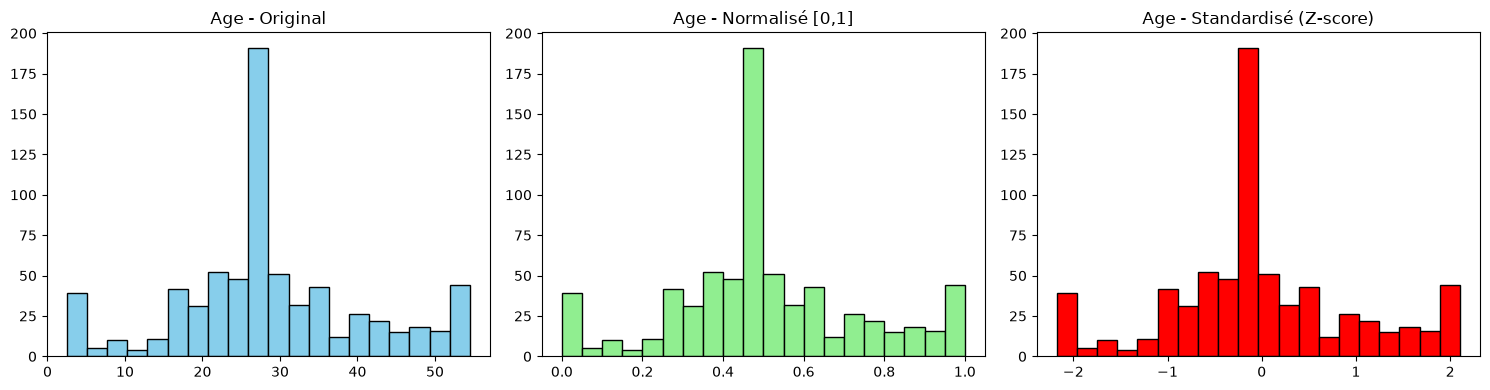

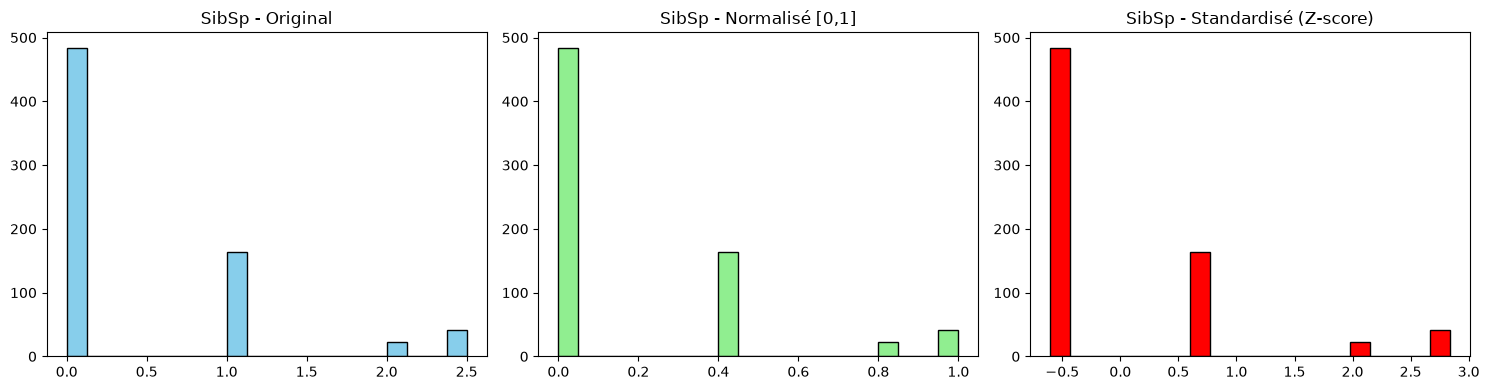

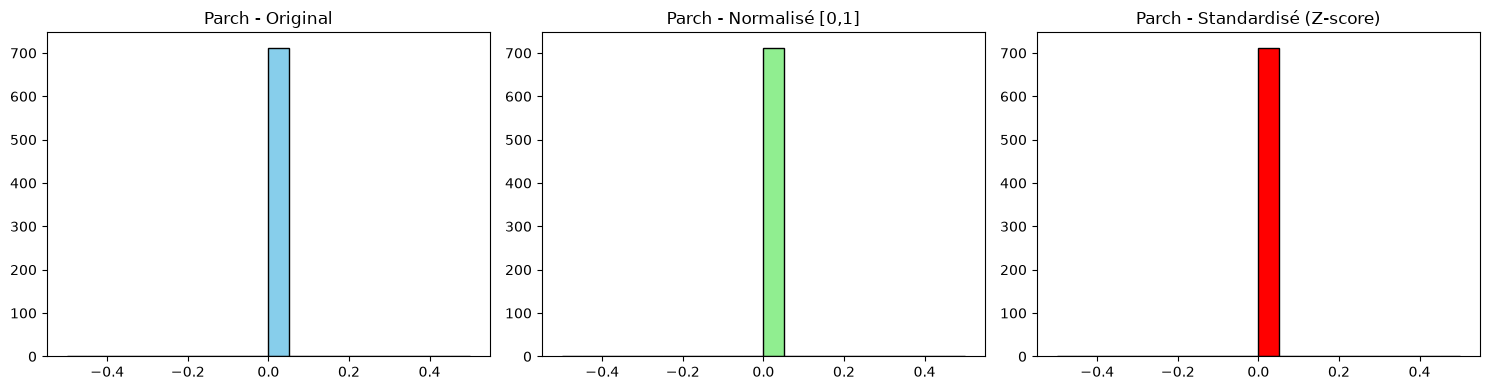

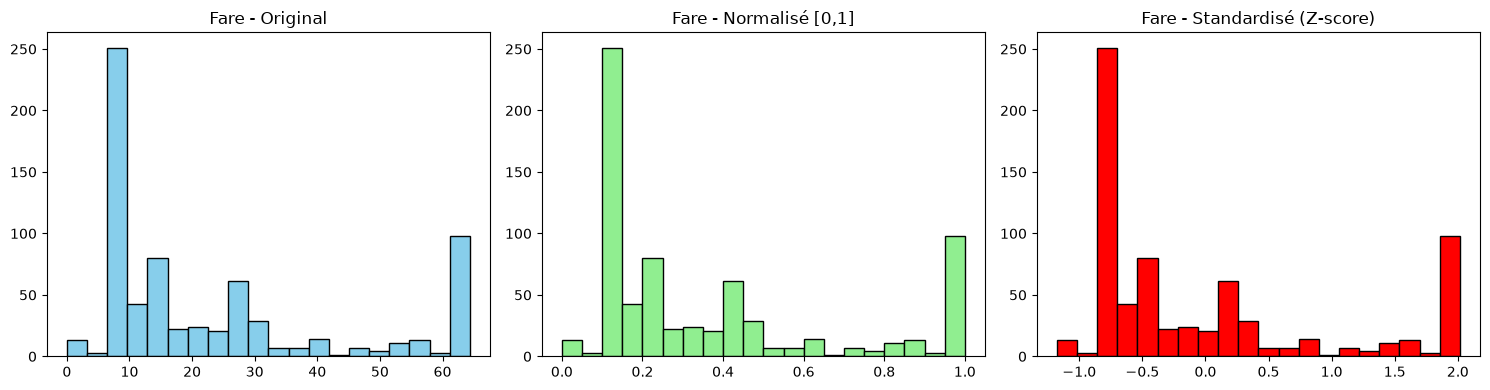

In [24]:
for col in colonnes_numeriques:
    plt.figure(figsize=(15,4))
    
    plt.subplot(1,3,1)
    plt.hist(X_train[col], bins=20, color='skyblue', edgecolor='black')
    plt.title(f"{col} - Original")
    
    plt.subplot(1,3,2)
    plt.hist(X_normalized[col], bins=20, color='lightgreen', edgecolor='black')
    plt.title(f"{col} - Normalisé [0,1]")
    
    plt.subplot(1,3,3)
    plt.hist(X_standardized[col], bins=20, color='red', edgecolor='black')
    plt.title(f"{col} - Standardisé (Z-score)")
    
    plt.tight_layout()
    plt.show()

## Data Test:

In [25]:
from sklearn.preprocessing import MinMaxScaler
colonnes_numeriques = X_test.select_dtypes(include=[np.number]).columns.tolist()
scaler_minmaxtest = MinMaxScaler()
#Normalisation (Min-Max scaling) : 
X_test_normalized =  X_test.copy()
X_test_normalized[colonnes_numeriques] = scaler_minmaxtest.fit_transform(X_test[colonnes_numeriques])
scaler_standardtest = StandardScaler()
#Standardisation
from sklearn.preprocessing import StandardScaler
X_test_standardized = X_test.copy()
X_test_standardized[colonnes_numeriques] = scaler_standardtest.fit_transform(X_test[colonnes_numeriques])

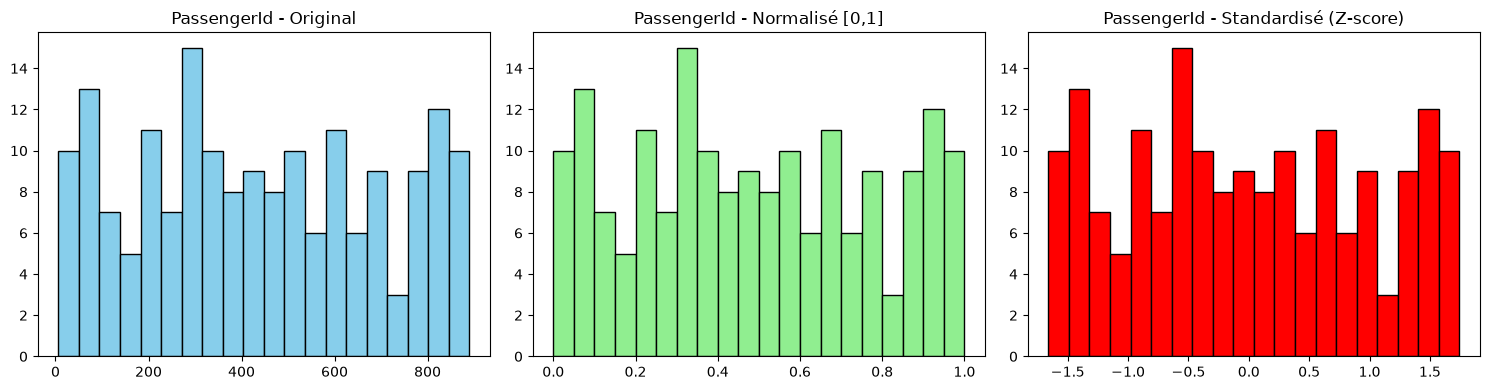

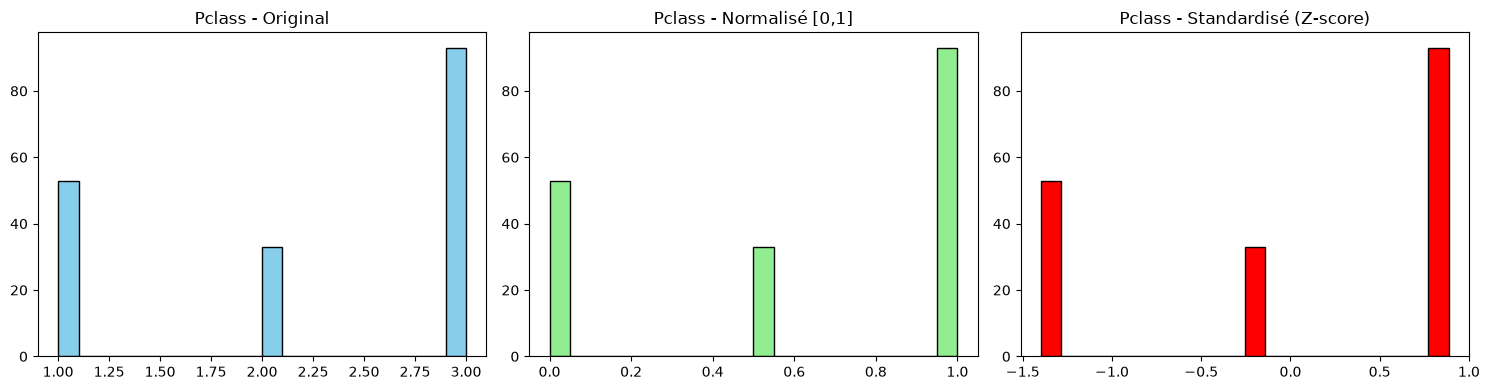

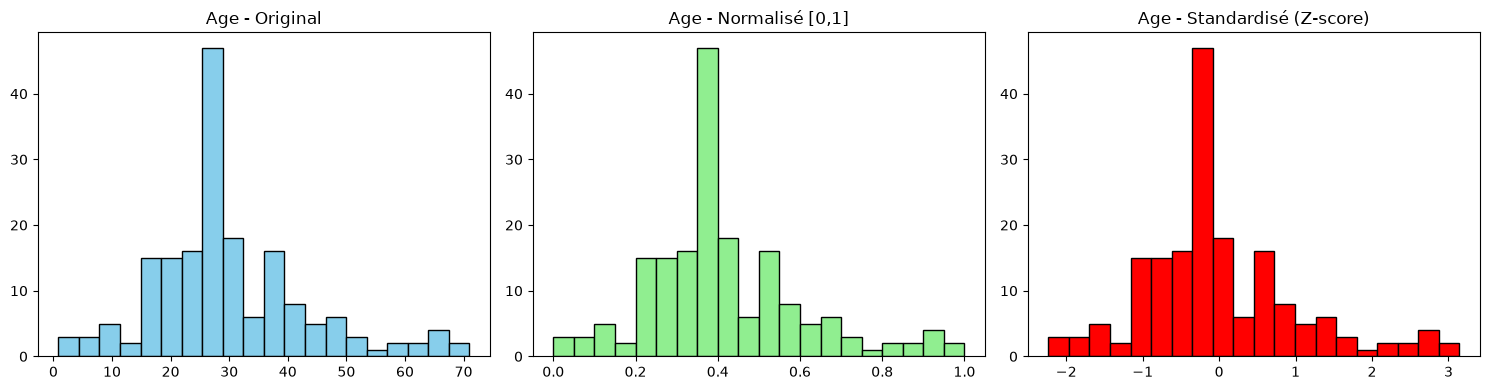

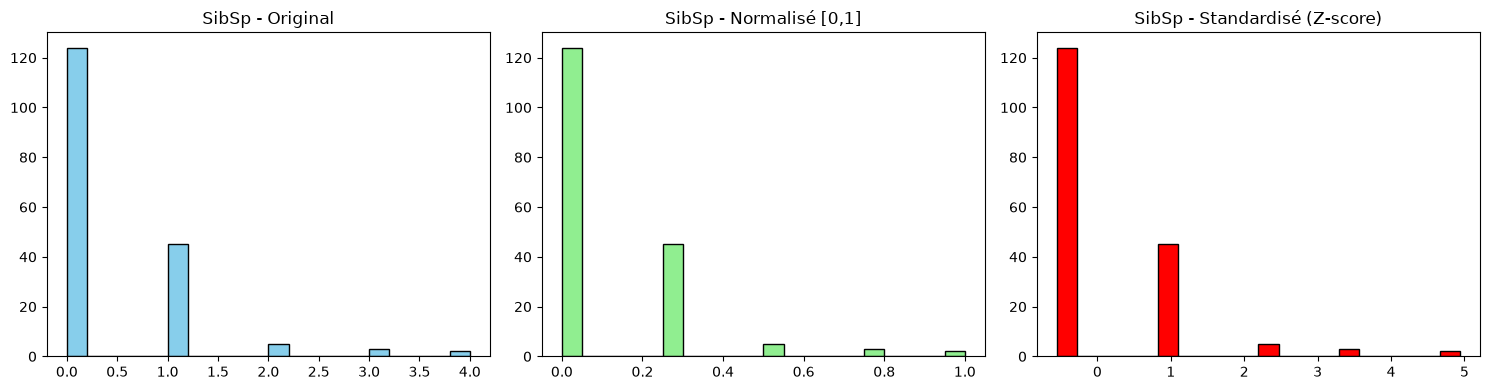

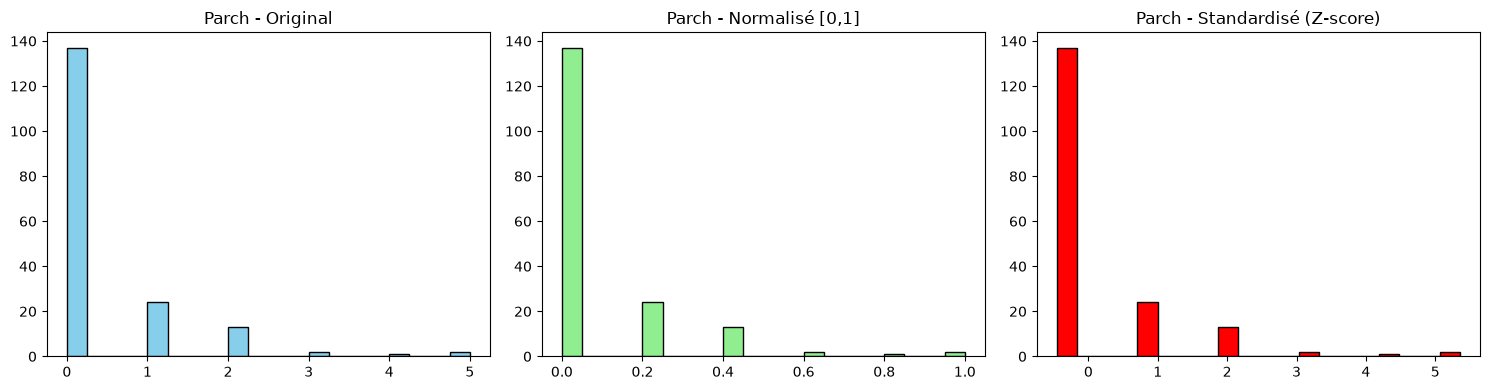

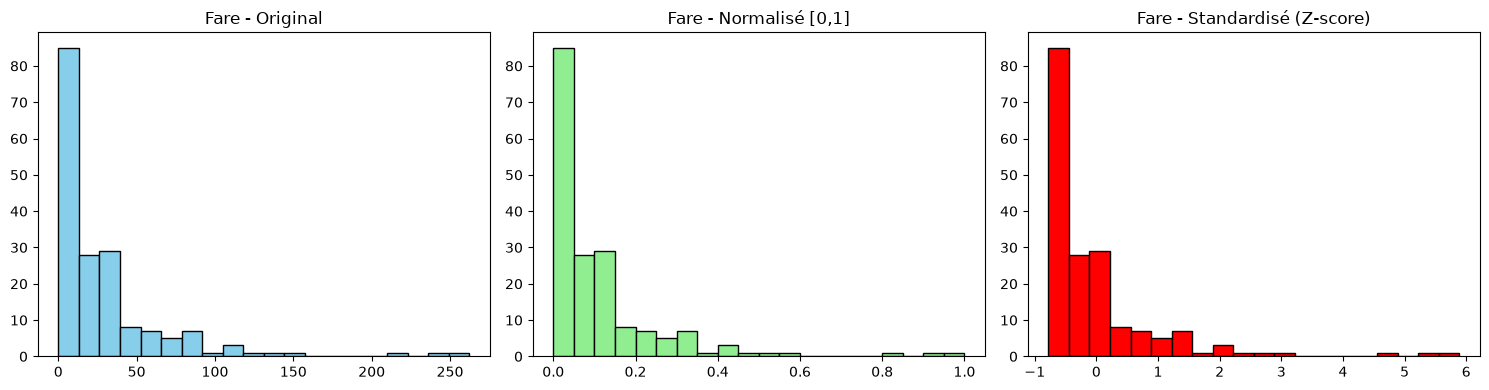

In [26]:
for col in colonnes_numeriques:
    plt.figure(figsize=(15,4))
    
    plt.subplot(1,3,1)
    plt.hist(X_test[col], bins=20, color='skyblue', edgecolor='black')
    plt.title(f"{col} - Original")
    
    plt.subplot(1,3,2)
    plt.hist(X_test_normalized[col], bins=20, color='lightgreen', edgecolor='black')
    plt.title(f"{col} - Normalisé [0,1]")
    
    plt.subplot(1,3,3)
    plt.hist(X_test_standardized[col], bins=20, color='red', edgecolor='black')
    plt.title(f"{col} - Standardisé (Z-score)")
    
    plt.tight_layout()
    plt.show()

## Partie 4 : Gestion des Données Déséquilibrées: 

###  1.Identification du déséquilibre des classes : 

In [27]:
# Compter le nombre d'exemples par classe
compte_classes = data['Survived'].value_counts()
print("Nombre d'exemples par classe :\n", compte_classes)



Nombre d'exemples par classe :
 Survived
0    549
1    342
Name: count, dtype: int64


### 2. Gestion du déséquilibre :

In [28]:
X_train=X_train.select_dtypes(include=['number'])

In [29]:
from imblearn.over_sampling import SMOTE

# Appliquer SMOTE
smote = SMOTE(random_state=42)

X_resampled, y_resampled = smote.fit_resample(
    X_train, y_train
)



# Afficher la distribution après SMOTE
print("\nDistribution après SMOTE :")
print(y_resampled.value_counts())


Distribution après SMOTE :
Survived
0    444
1    444
Name: count, dtype: int64
